# American Time Use Survey (ATUS) — Analysis

**Purpose**: Analyze time spent per week on household production by married men and women, broken out by whether they have children.

This notebook picks up where `01_extraction.ipynb` left off — using the extracted CSV to produce tables, charts, and narrative findings.

**The core question**: When media reports say "men don't share the housework," what are they counting? If you only count *housework* (cleaning, cooking, laundry), women do substantially more. But if you count *everything a couple must do to maintain a household* — including market labor, commute, childcare, home maintenance, shopping, volunteering, coaching kids' teams, and all the travel those require — does the picture change?

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

os.makedirs('figures', exist_ok=True)
os.makedirs('household_production_files', exist_ok=True)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Color palette: blue for men, orange for women; solid for with-kids, lighter for no-kids
PALETTE = {
    'Men w/ kids':   '#2166ac',
    'Men no kids':    '#67a9cf',
    'Women w/ kids':  '#b2182b',
    'Women no kids':  '#ef8a62',
}

# ATUS diary day is a single day; we convert to weekly by ×7
# Minutes/day → hours/week: multiply by 7, divide by 60
MIN_DAY_TO_HRS_WEEK = 7 / 60

## 2. Load Extracted Data

In [2]:
df = pd.read_csv('data/atus_extracted.csv')
print(f'Loaded {len(df):,} married respondents')
print(f'Groups:')
print(df['group'].value_counts().to_string())

# Activity category columns
category_cols = [
    'housework_home_maintenance',
    'childcare_household',
    'care_nonhh_members',
    'market_labor',
    'shopping',
    'prof_personal_services',
    'household_services',
    'civic_gov',
    'volunteer',
    'commute',
    'travel_housework',
    'travel_childcare',
    'travel_nonhh_care',
    'travel_shopping',
    'travel_volunteer',
    'travel_civic',
]

# Group order
GROUPS = ['Men w/ kids', 'Men no kids', 'Women w/ kids', 'Women no kids']

# Friendly labels for charts
CATEGORY_LABELS = {
    'housework_home_maintenance': 'Housework &\nHome Maintenance',
    'childcare_household': 'Childcare\n(household)',
    'care_nonhh_members': 'Care for\nNon-HH Members',
    'market_labor': 'Market Labor',
    'shopping': 'Shopping',
    'prof_personal_services': 'Prof & Personal\nServices',
    'household_services': 'Household\nServices',
    'civic_gov': 'Civic & Gov',
    'volunteer': 'Volunteer',
    'commute': 'Commute',
    'travel_housework': 'Travel:\nHousework',
    'travel_childcare': 'Travel:\nChildcare',
    'travel_nonhh_care': 'Travel:\nNon-HH Care',
    'travel_shopping': 'Travel:\nShopping',
    'travel_volunteer': 'Travel:\nVolunteer',
    'travel_civic': 'Travel:\nCivic',
}

Loaded 4,571 married respondents
Groups:
group
Women w/ kids    1201
Men w/ kids      1170
Women no kids    1117
Men no kids      1083


## 3. Weighted Mean Hours per Week

Compute weighted means using ATUS final weights (`tufinlwgt`), converting from minutes per diary day to hours per week.

In [3]:
def weighted_mean(df, values, weights='tufinlwgt'):
    '''Compute weighted mean for a single column.'''
    return (df[values] * df[weights]).sum() / df[weights].sum()

# Build summary table: hours per week
summary = pd.DataFrame(index=GROUPS)
for grp in GROUPS:
    subset = df[df['group'] == grp]
    for col in category_cols + ['total_household_production']:
        summary.loc[grp, col] = weighted_mean(subset, col) * MIN_DAY_TO_HRS_WEEK

summary = summary.round(1)

print('Hours per week (weighted means)')
print('=' * 100)
# Print with nice formatting
display_df = summary.copy()
display_df.columns = [c.replace('_', ' ').title() for c in display_df.columns]
print(display_df.to_string())

Hours per week (weighted means)
               Housework Home Maintenance  Childcare Household  Care Nonhh Members  Market Labor  Shopping  Prof Personal Services  Household Services  Civic Gov  Volunteer  Commute  Travel Housework  Travel Childcare  Travel Nonhh Care  Travel Shopping  Travel Volunteer  Travel Civic  Total Household Production
Men w/ kids                           9.8                  6.2                 0.5          38.3       2.1                     0.3                 0.2        0.1        0.9      3.5               0.3               1.1                0.1              1.6               0.1           0.0                        65.1
Men no kids                          12.7                  0.5                 1.7          23.4       1.9                     0.9                 0.3        0.1        1.0      2.3               0.3               0.2                0.4              1.6               0.2           0.0                        47.5
Women w/ kids             

## 4. The Big Picture: Total Household Production

When you count *everything* a couple must do to maintain a household, how do men and women compare?

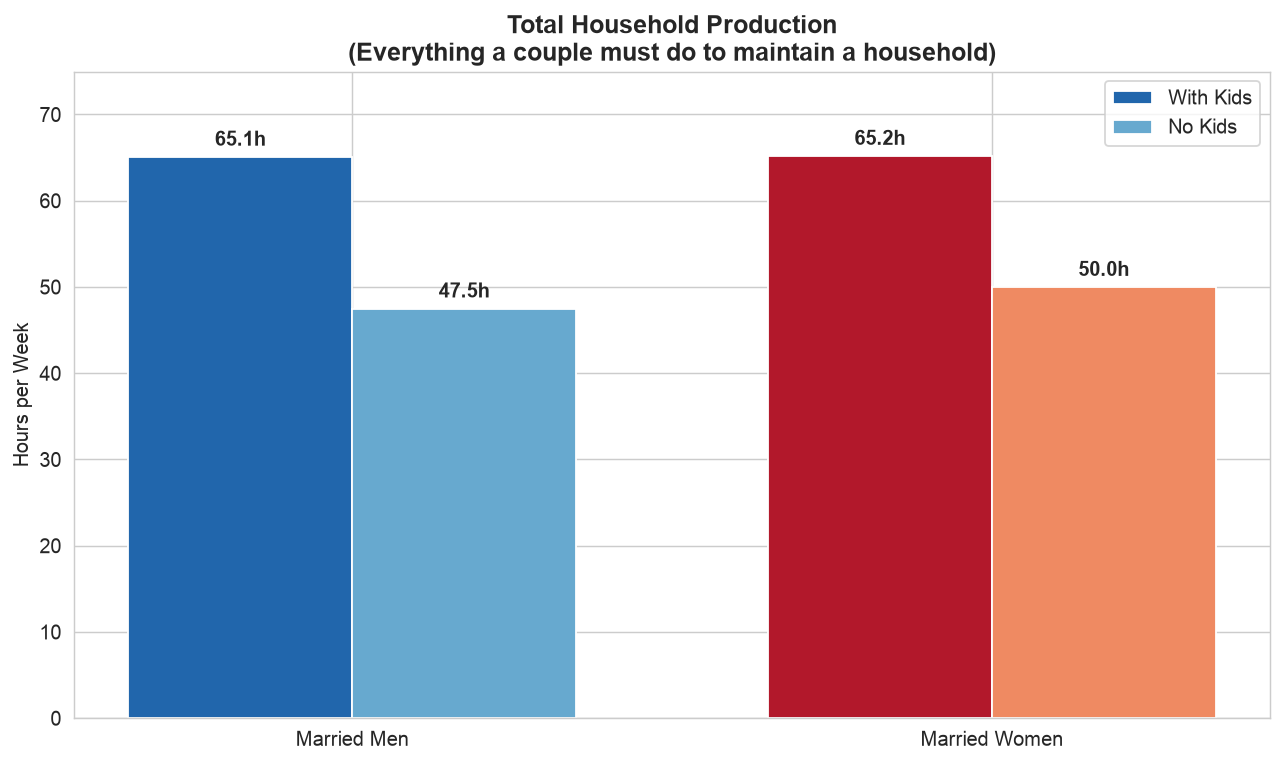


With Kids:
  Married Men:   65.1 hrs/week
  Married Women: 65.2 hrs/week
  Difference:    -0.1 hrs/week

Without Kids:
  Married Men:   47.5 hrs/week
  Married Women: 50.0 hrs/week
  Difference:    -2.5 hrs/week


In [4]:
fig, ax = plt.subplots(figsize=(10, 6))

groups_with_kids = ['Men w/ kids', 'Women w/ kids']
groups_no_kids = ['Men no kids', 'Women no kids']

x = np.arange(len(groups_with_kids))
width = 0.35

vals_kids = [summary.loc[g, 'total_household_production'] for g in groups_with_kids]
vals_no_kids = [summary.loc[g, 'total_household_production'] for g in groups_no_kids]

bars1 = ax.bar(x - width/2, vals_kids, width, label='With Kids',
               color=[PALETTE['Men w/ kids'], PALETTE['Women w/ kids']])
bars2 = ax.bar(x + width/2, vals_no_kids, width, label='No Kids',
               color=[PALETTE['Men no kids'], PALETTE['Women no kids']])

ax.set_ylabel('Hours per Week')
ax.set_title('Total Household Production\n(Everything a couple must do to maintain a household)')
ax.set_xticks(x)
ax.set_xticklabels(['Married Men', 'Married Women'])
ax.legend()

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.8, f'{h:.1f}h',
                ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, max(vals_kids + vals_no_kids) * 1.15)
plt.tight_layout()
plt.savefig('figures/total_household_production.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nWith Kids:')
print(f'  Married Men:   {summary.loc["Men w/ kids", "total_household_production"]:.1f} hrs/week')
print(f'  Married Women: {summary.loc["Women w/ kids", "total_household_production"]:.1f} hrs/week')
print(f'  Difference:    {summary.loc["Men w/ kids", "total_household_production"] - summary.loc["Women w/ kids", "total_household_production"]:.1f} hrs/week')
print()
print('Without Kids:')
print(f'  Married Men:   {summary.loc["Men no kids", "total_household_production"]:.1f} hrs/week')
print(f'  Married Women: {summary.loc["Women no kids", "total_household_production"]:.1f} hrs/week')
print(f'  Difference:    {summary.loc["Men no kids", "total_household_production"] - summary.loc["Women no kids", "total_household_production"]:.1f} hrs/week')

## 5. Composition: What Makes Up Household Production?

Stacked bar charts showing how each group allocates their time across the 16 categories.

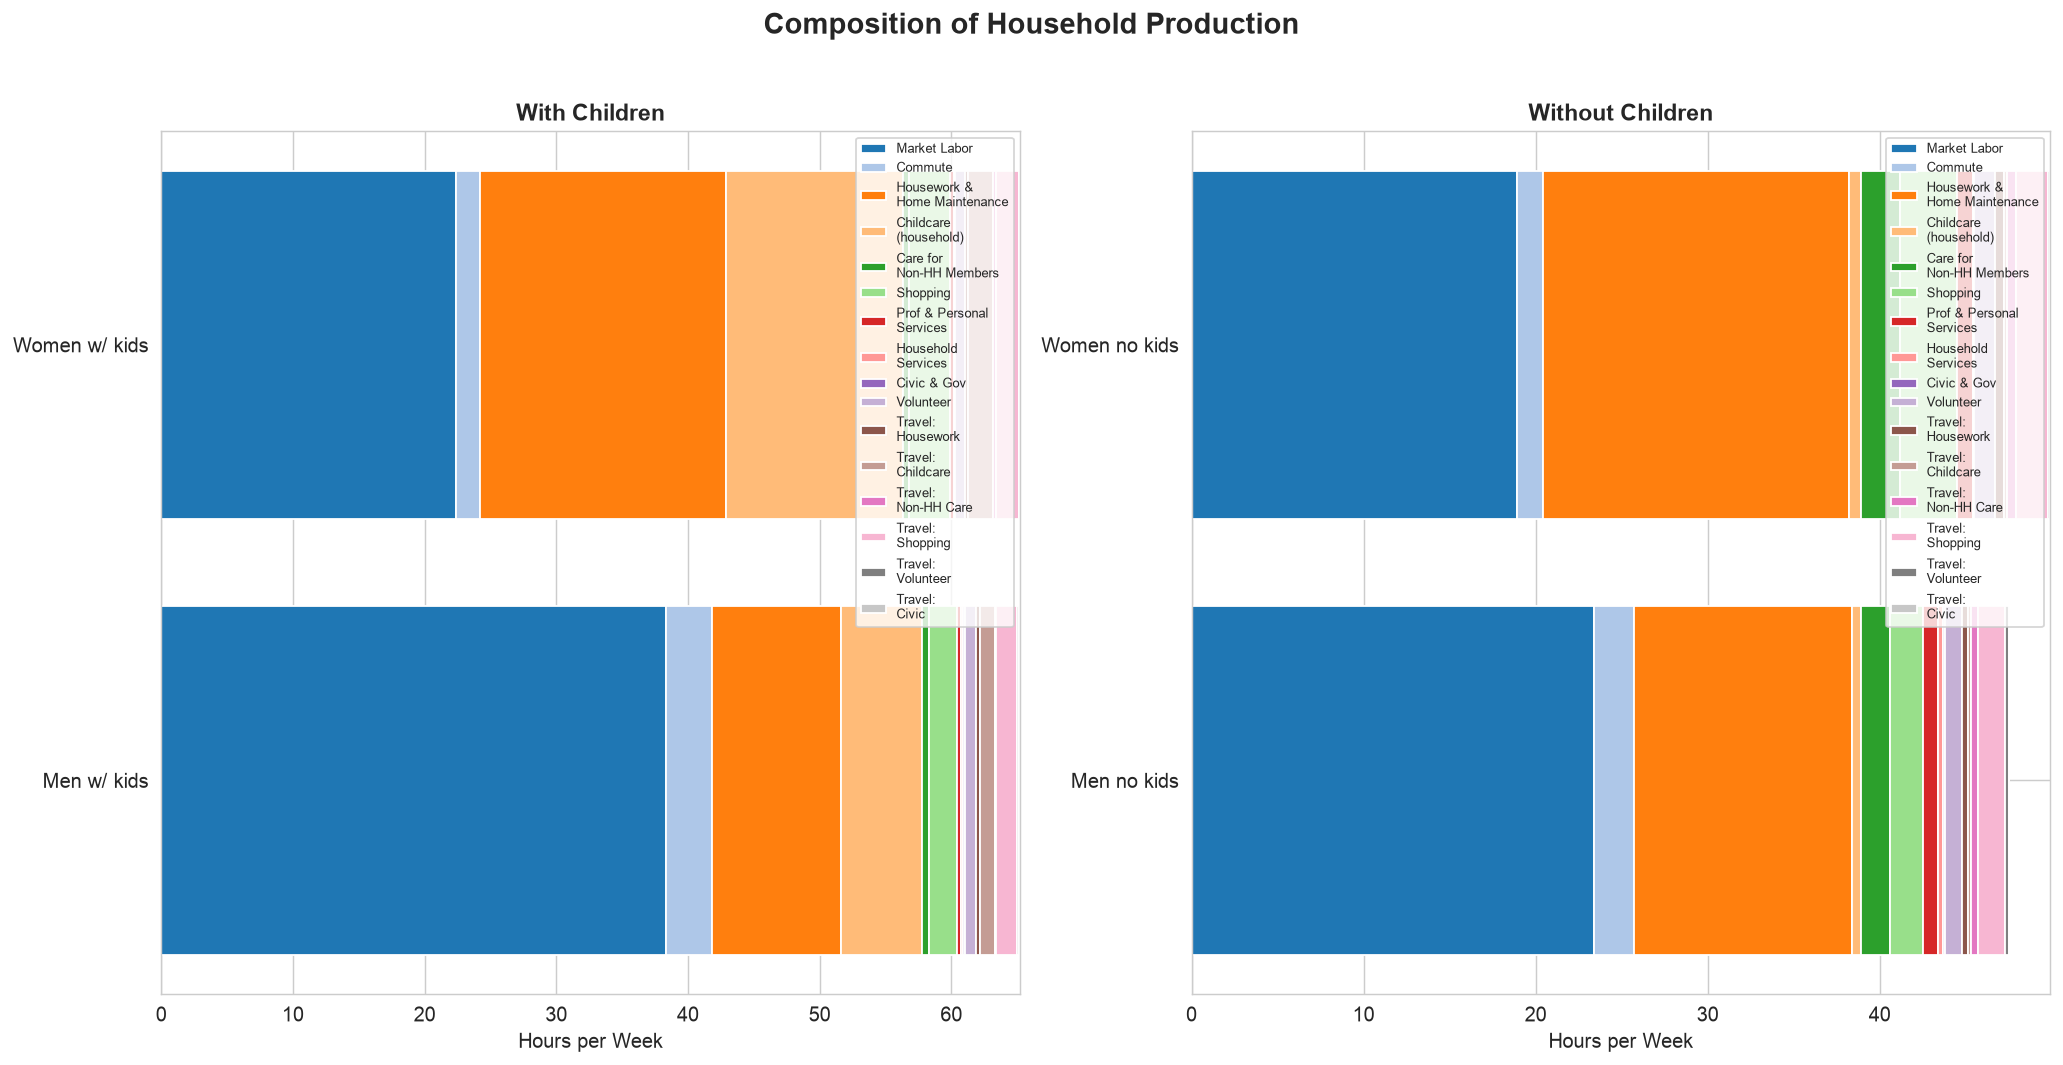

In [5]:
# Group categories for a cleaner stacked chart
major_categories = [
    'market_labor',
    'commute',
    'housework_home_maintenance',
    'childcare_household',
    'care_nonhh_members',
    'shopping',
    'prof_personal_services',
    'household_services',
    'civic_gov',
    'volunteer',
    'travel_housework',
    'travel_childcare',
    'travel_nonhh_care',
    'travel_shopping',
    'travel_volunteer',
    'travel_civic',
]

major_labels = [CATEGORY_LABELS.get(c, c) for c in major_categories]

# Build the stacked data
stacked_data = summary[major_categories].copy()

# Colors: a diverging palette
colors = sns.color_palette('tab20', len(major_categories))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# --- Left: With Kids ---
ax = axes[0]
groups_kids = ['Men w/ kids', 'Women w/ kids']
data_kids = stacked_data.loc[groups_kids].T  # categories as rows, groups as cols

bottom = np.zeros(len(groups_kids))
for i, (cat, label) in enumerate(zip(major_categories, major_labels)):
    vals = data_kids.loc[cat].values
    ax.barh(groups_kids, vals, left=bottom, label=label, color=colors[i])
    bottom += vals

ax.set_xlabel('Hours per Week')
ax.set_title('With Children', fontsize=13)
ax.legend(loc='upper right', fontsize=7, ncol=1)

# --- Right: No Kids ---
ax = axes[1]
groups_no = ['Men no kids', 'Women no kids']
data_no = stacked_data.loc[groups_no].T

bottom = np.zeros(len(groups_no))
for i, (cat, label) in enumerate(zip(major_categories, major_labels)):
    vals = data_no.loc[cat].values
    ax.barh(groups_no, vals, left=bottom, label=label, color=colors[i])
    bottom += vals

ax.set_xlabel('Hours per Week')
ax.set_title('Without Children', fontsize=13)
ax.legend(loc='upper right', fontsize=7, ncol=1)

plt.suptitle('Composition of Household Production', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/composition_stacked.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Side-by-Side: Men vs Women, Category by Category

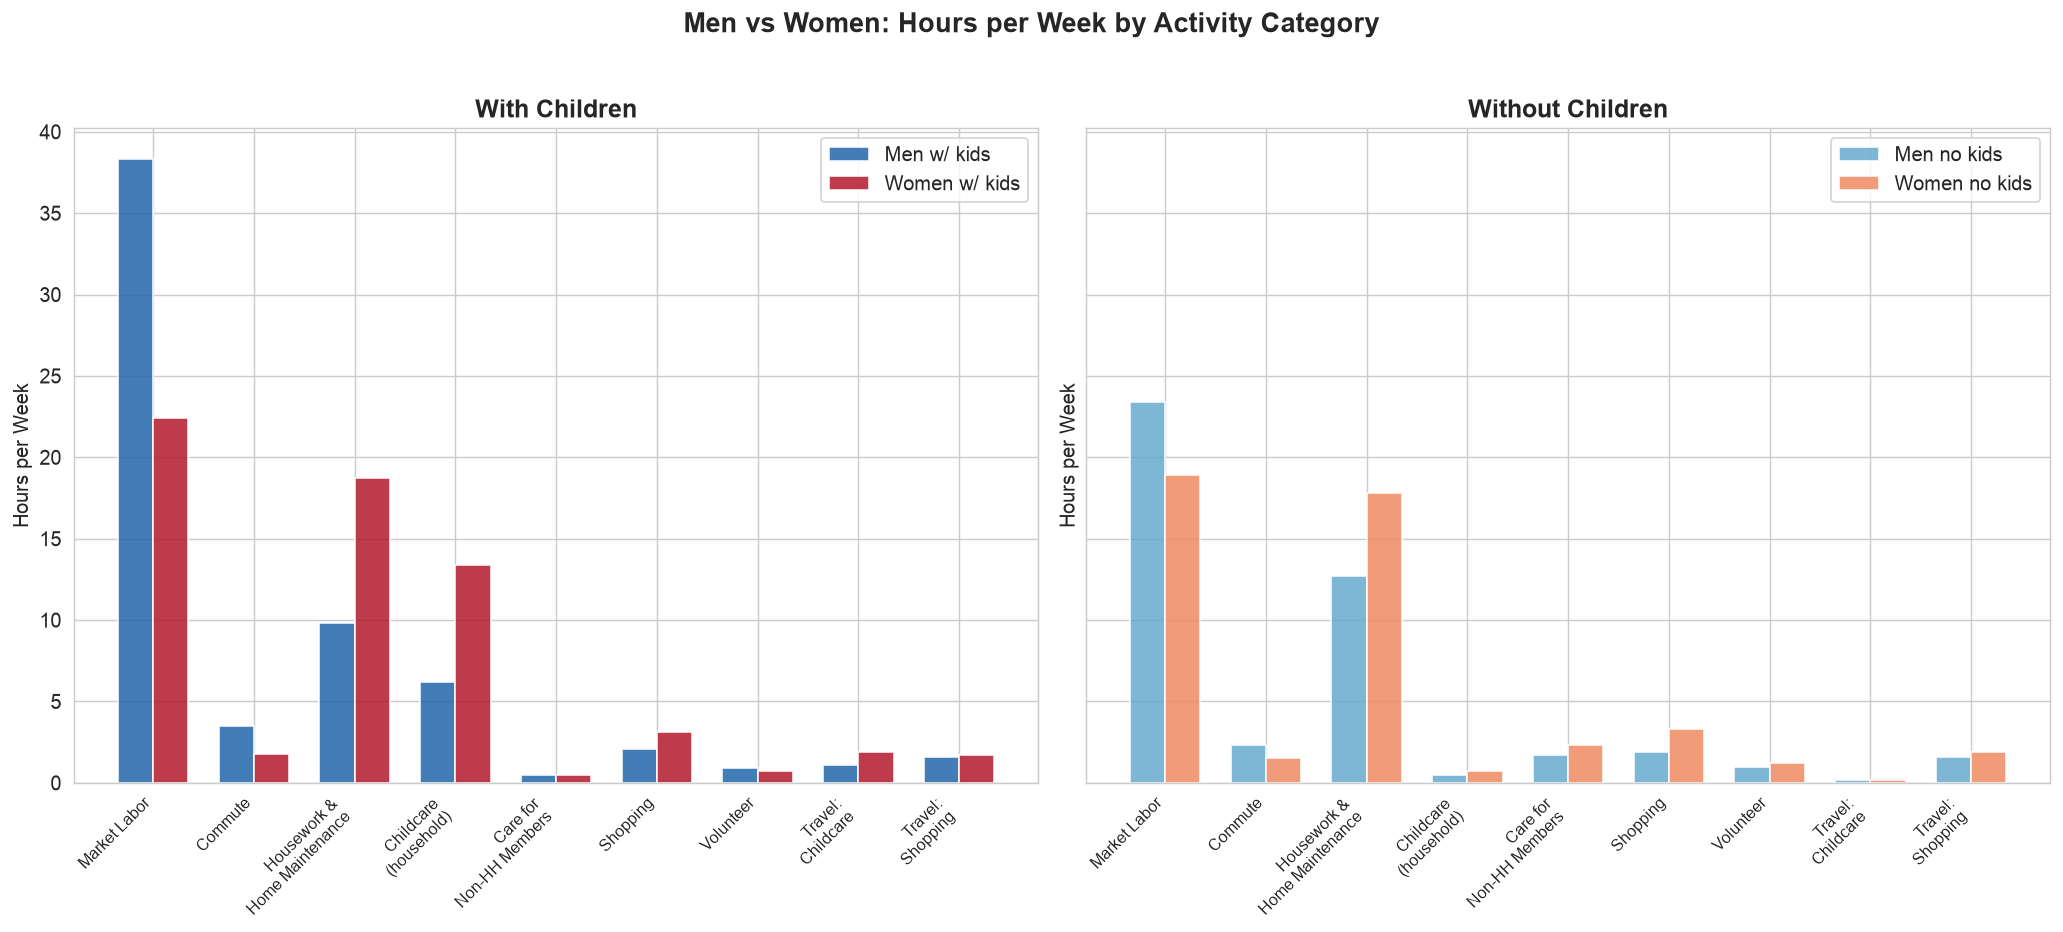

In [6]:
# Focus on the key categories (exclude tiny ones for readability)
key_cats = [
    'market_labor', 'commute', 'housework_home_maintenance',
    'childcare_household', 'care_nonhh_members', 'shopping',
    'volunteer', 'travel_childcare', 'travel_shopping',
]
key_labels = [CATEGORY_LABELS.get(c, c).replace('\\n', ' ') for c in key_cats]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for ax, kid_status, groups in [
    (axes[0], 'With Children', ['Men w/ kids', 'Women w/ kids']),
    (axes[1], 'Without Children', ['Men no kids', 'Women no kids']),
]:
    x = np.arange(len(key_cats))
    width = 0.35

    men_vals = [summary.loc[groups[0], c] for c in key_cats]
    women_vals = [summary.loc[groups[1], c] for c in key_cats]

    ax.bar(x - width/2, men_vals, width, label=groups[0],
           color=PALETTE[groups[0]], alpha=0.85)
    ax.bar(x + width/2, women_vals, width, label=groups[1],
           color=PALETTE[groups[1]], alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(key_labels, rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('Hours per Week')
    ax.set_title(kid_status)
    ax.legend()

plt.suptitle('Men vs Women: Hours per Week by Activity Category',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/men_vs_women.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. The "Housework Only" vs "Everything" Comparison

This is the key chart. Media reports typically compare only "housework" (cleaning, cooking, laundry). Here we show what happens when you add more categories.

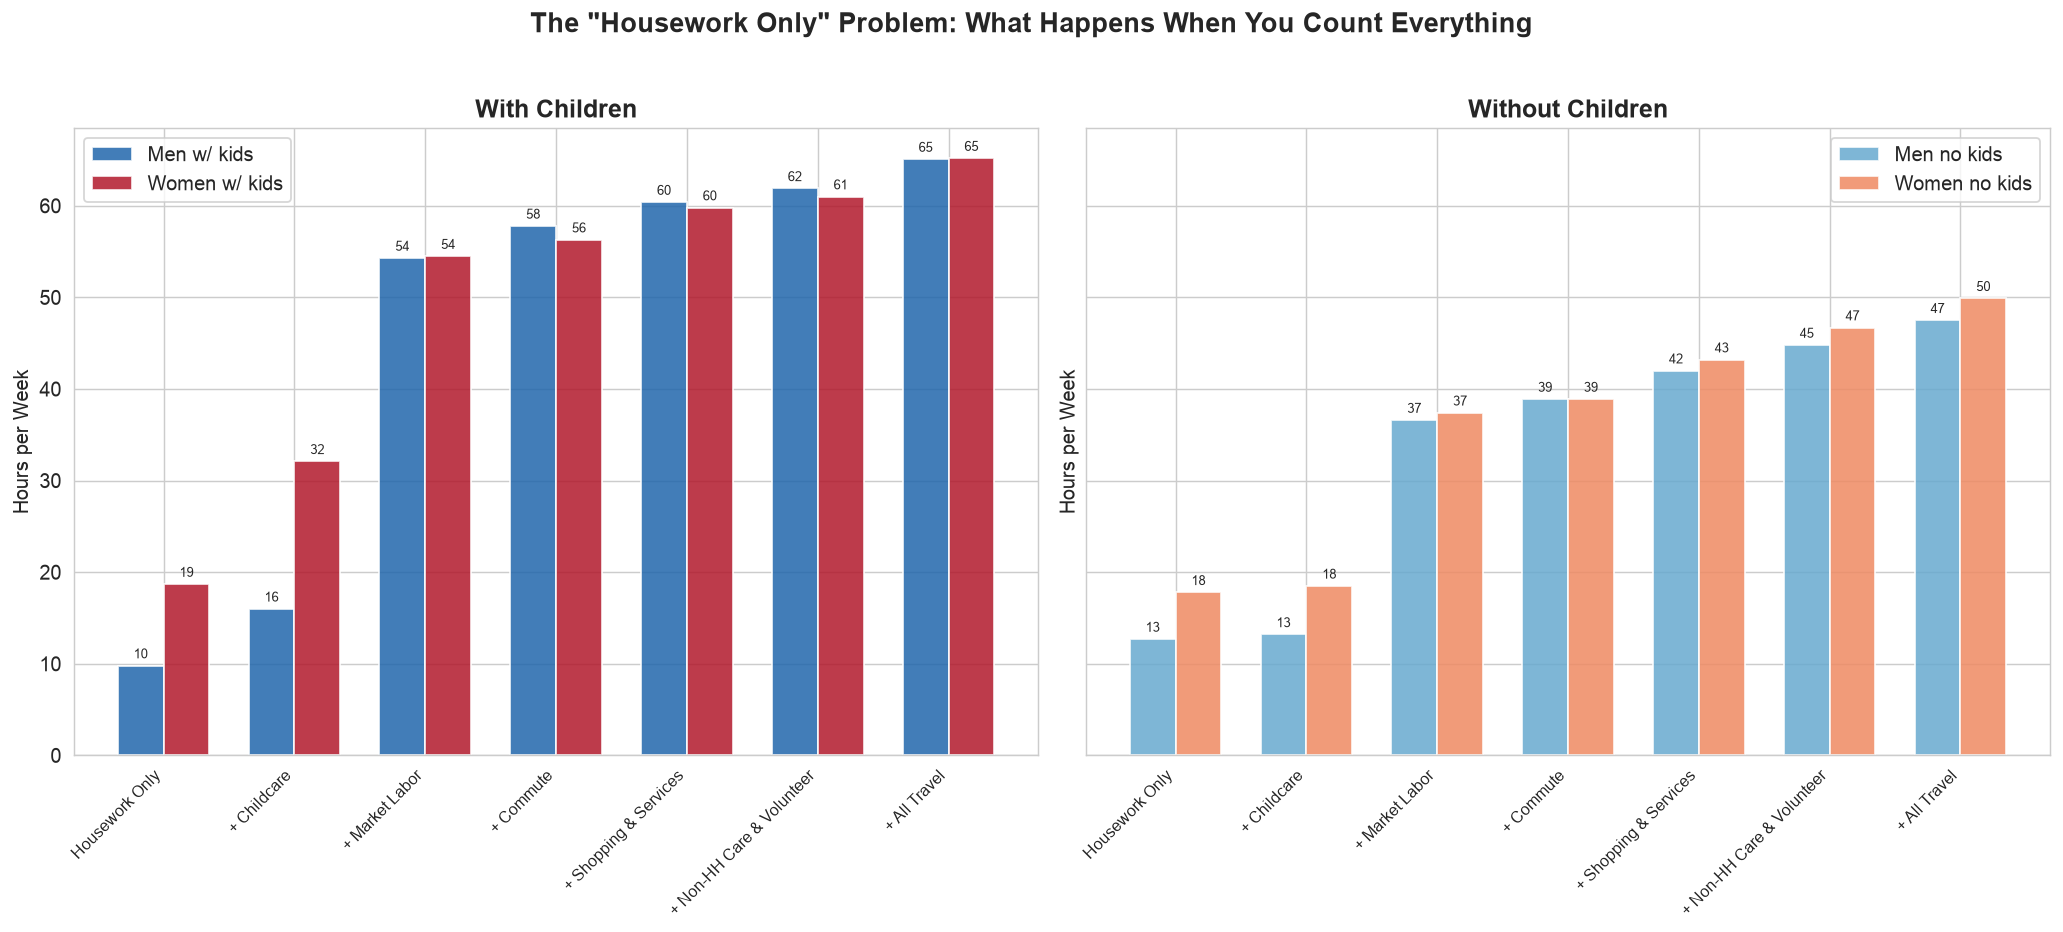


Ratio (Women / Men) at each step:

  With Kids:
    Housework Only                : Men=  9.8h  Women= 18.7h  Ratio=1.91
    + Childcare                   : Men= 16.0h  Women= 32.1h  Ratio=2.01
    + Market Labor                : Men= 54.3h  Women= 54.5h  Ratio=1.00
    + Commute                     : Men= 57.8h  Women= 56.3h  Ratio=0.97
    + Shopping & Services         : Men= 60.4h  Women= 59.8h  Ratio=0.99
    + Non-HH Care & Volunteer     : Men= 61.9h  Women= 61.0h  Ratio=0.99
    + All Travel                  : Men= 65.1h  Women= 65.2h  Ratio=1.00

  No Kids:
    Housework Only                : Men= 12.7h  Women= 17.8h  Ratio=1.40
    + Childcare                   : Men= 13.2h  Women= 18.5h  Ratio=1.40
    + Market Labor                : Men= 36.6h  Women= 37.4h  Ratio=1.02
    + Commute                     : Men= 38.9h  Women= 38.9h  Ratio=1.00
    + Shopping & Services         : Men= 42.0h  Women= 43.2h  Ratio=1.03
    + Non-HH Care & Volunteer     : Men= 44.8h  Women= 46.7h  R

In [7]:
# Define progressive accumulation of categories
accumulation_steps = [
    ('Housework Only',
     ['housework_home_maintenance']),
    ('+ Childcare',
     ['housework_home_maintenance', 'childcare_household']),
    ('+ Market Labor',
     ['housework_home_maintenance', 'childcare_household', 'market_labor']),
    ('+ Commute',
     ['housework_home_maintenance', 'childcare_household', 'market_labor', 'commute']),
    ('+ Shopping & Services',
     ['housework_home_maintenance', 'childcare_household', 'market_labor', 'commute',
      'shopping', 'prof_personal_services', 'household_services']),
    ('+ Non-HH Care & Volunteer',
     ['housework_home_maintenance', 'childcare_household', 'market_labor', 'commute',
      'shopping', 'prof_personal_services', 'household_services',
      'care_nonhh_members', 'civic_gov', 'volunteer']),
    ('+ All Travel',
     category_cols),  # everything
]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for ax, kid_status, groups in [
    (axes[0], 'With Children', ['Men w/ kids', 'Women w/ kids']),
    (axes[1], 'Without Children', ['Men no kids', 'Women no kids']),
]:
    x = np.arange(len(accumulation_steps))
    width = 0.35

    men_vals = []
    women_vals = []
    for label, cols in accumulation_steps:
        men_vals.append(summary.loc[groups[0], cols].sum())
        women_vals.append(summary.loc[groups[1], cols].sum())

    ax.bar(x - width/2, men_vals, width, label=groups[0],
           color=PALETTE[groups[0]], alpha=0.85)
    ax.bar(x + width/2, women_vals, width, label=groups[1],
           color=PALETTE[groups[1]], alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels([s[0] for s in accumulation_steps], rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('Hours per Week')
    ax.set_title(kid_status)
    ax.legend()

    # Add value labels
    for i, (mv, wv) in enumerate(zip(men_vals, women_vals)):
        ax.text(i - width/2, mv + 0.5, f'{mv:.0f}', ha='center', va='bottom', fontsize=7)
        ax.text(i + width/2, wv + 0.5, f'{wv:.0f}', ha='center', va='bottom', fontsize=7)

plt.suptitle('The \"Housework Only\" Problem: What Happens When You Count Everything',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/accumulation.png', dpi=150, bbox_inches='tight')
plt.show()

# Print the ratio at each step
print('\nRatio (Women / Men) at each step:')
for kid_status, groups in [('With Kids', ['Men w/ kids', 'Women w/ kids']),
                            ('No Kids', ['Men no kids', 'Women no kids'])]:
    print(f'\n  {kid_status}:')
    for label, cols in accumulation_steps:
        m = summary.loc[groups[0], cols].sum()
        w = summary.loc[groups[1], cols].sum()
        ratio = w / m if m > 0 else float('inf')
        print(f'    {label:30s}: Men={m:5.1f}h  Women={w:5.1f}h  Ratio={ratio:.2f}')

## 8. The Gender Gap: Men's Minus Women's Time

A positive value means men spend more time; negative means women spend more.

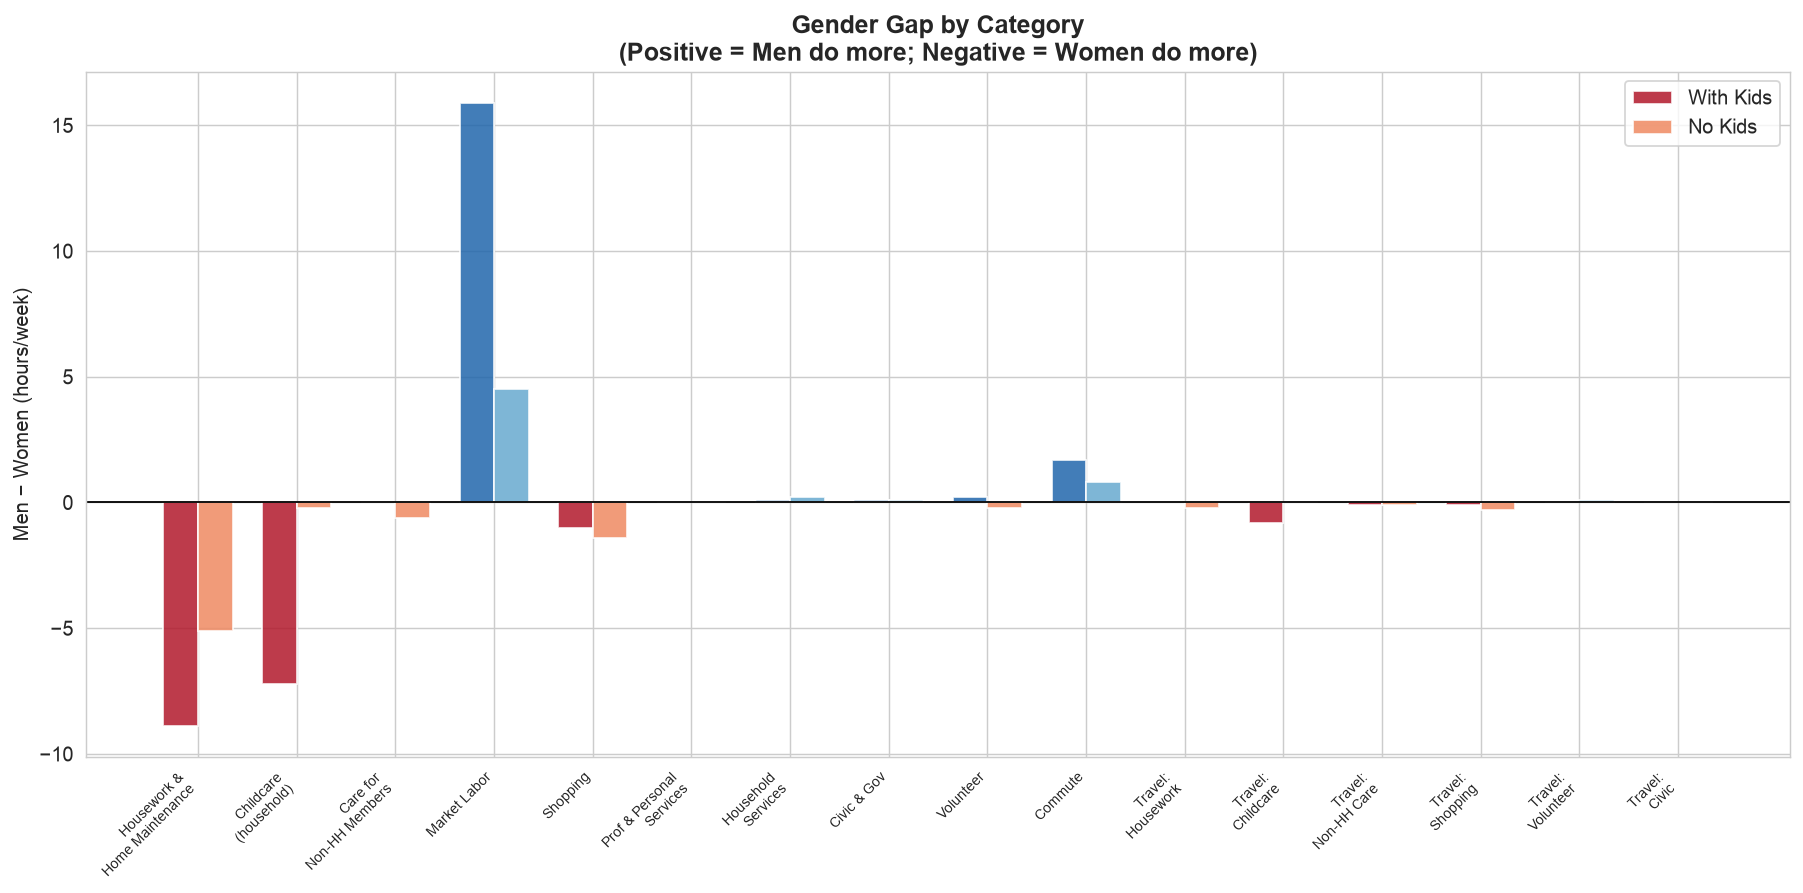

In [8]:
fig, ax = plt.subplots(figsize=(14, 7))

# For each category, compute men - women (with kids)
gaps_kids = []
gaps_no_kids = []
labels = []

for col in category_cols:
    labels.append(CATEGORY_LABELS.get(col, col).replace('\\n', ' '))
    gap_k = summary.loc['Men w/ kids', col] - summary.loc['Women w/ kids', col]
    gap_nk = summary.loc['Men no kids', col] - summary.loc['Women no kids', col]
    gaps_kids.append(gap_k)
    gaps_no_kids.append(gap_nk)

x = np.arange(len(labels))
width = 0.35

colors_kids = ['#2166ac' if g >= 0 else '#b2182b' for g in gaps_kids]
colors_no = ['#67a9cf' if g >= 0 else '#ef8a62' for g in gaps_no_kids]

ax.bar(x - width/2, gaps_kids, width, label='With Kids', color=colors_kids, alpha=0.85)
ax.bar(x + width/2, gaps_no_kids, width, label='No Kids', color=colors_no, alpha=0.85)

ax.axhline(0, color='black', linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Men − Women (hours/week)')
ax.set_title('Gender Gap by Category\n(Positive = Men do more; Negative = Women do more)')
ax.legend()

plt.tight_layout()
plt.savefig('figures/gender_gap.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Detailed Table: All Categories, All Groups

In [9]:
# Full table with readable column names
table = summary[category_cols + ['total_household_production']].copy()
table.columns = [c.replace('_', ' ').title() for c in table.columns]
table.index.name = 'Group'

print('Hours per Week (Weighted Means)')
print('=' * 120)
print(table.to_string())

# Also save to CSV
table.to_csv('data/summary_hours_per_week.csv')
print('\n\nSaved to data/summary_hours_per_week.csv')

Hours per Week (Weighted Means)
               Housework Home Maintenance  Childcare Household  Care Nonhh Members  Market Labor  Shopping  Prof Personal Services  Household Services  Civic Gov  Volunteer  Commute  Travel Housework  Travel Childcare  Travel Nonhh Care  Travel Shopping  Travel Volunteer  Travel Civic  Total Household Production
Group                                                                                                                                                                                                                                                                                                                    
Men w/ kids                           9.8                  6.2                 0.5          38.3       2.1                     0.3                 0.2        0.1        0.9      3.5               0.3               1.1                0.1              1.6               0.1           0.0                        65.1
Men no kids               

## 10. Men's Share of Total

For married couples with kids, what percentage of total household production do men contribute?

In [10]:
men_total = summary.loc['Men w/ kids', 'total_household_production']
women_total = summary.loc['Women w/ kids', 'total_household_production']
couple_total = men_total + women_total

print('Married Couples with Children — Household Production')
print('=' * 60)
print(f'  Men:   {men_total:.1f} hrs/week  ({men_total/couple_total*100:.1f}% of couple total)')
print(f'  Women: {women_total:.1f} hrs/week  ({women_total/couple_total*100:.1f}% of couple total)')
print(f'  Total: {couple_total:.1f} hrs/week')
print()

# Per-category shares
print('\nMen\'s share within each category (couples with kids):')
print('-' * 60)
for col in category_cols:
    m = summary.loc['Men w/ kids', col]
    w = summary.loc['Women w/ kids', col]
    total = m + w
    if total > 0:
        share = m / total * 100
        label = col.replace('_', ' ').title()
        print(f'  {label:35s}: {share:5.1f}%  (M={m:.1f}h, W={w:.1f}h)')

print()
print('\nMen\'s share within each category (couples without kids):')
print('-' * 60)
for col in category_cols:
    m = summary.loc['Men no kids', col]
    w = summary.loc['Women no kids', col]
    total = m + w
    if total > 0:
        share = m / total * 100
        label = col.replace('_', ' ').title()
        print(f'  {label:35s}: {share:5.1f}%  (M={m:.1f}h, W={w:.1f}h)')

Married Couples with Children — Household Production
  Men:   65.1 hrs/week  (50.0% of couple total)
  Women: 65.2 hrs/week  (50.0% of couple total)
  Total: 130.3 hrs/week


Men's share within each category (couples with kids):
------------------------------------------------------------
  Housework Home Maintenance         :  34.4%  (M=9.8h, W=18.7h)
  Childcare Household                :  31.6%  (M=6.2h, W=13.4h)
  Care Nonhh Members                 :  50.0%  (M=0.5h, W=0.5h)
  Market Labor                       :  63.1%  (M=38.3h, W=22.4h)
  Shopping                           :  40.4%  (M=2.1h, W=3.1h)
  Prof Personal Services             :  50.0%  (M=0.3h, W=0.3h)
  Household Services                 :  66.7%  (M=0.2h, W=0.1h)
  Civic Gov                          : 100.0%  (M=0.1h, W=0.0h)
  Volunteer                          :  56.2%  (M=0.9h, W=0.7h)
  Commute                            :  66.0%  (M=3.5h, W=1.8h)
  Travel Housework                   :  50.0%  (M=0.3h, W=0.3h)
  

## 11. The Narrow vs. Broad View

A clear comparison of what different definitions of "household production" show.

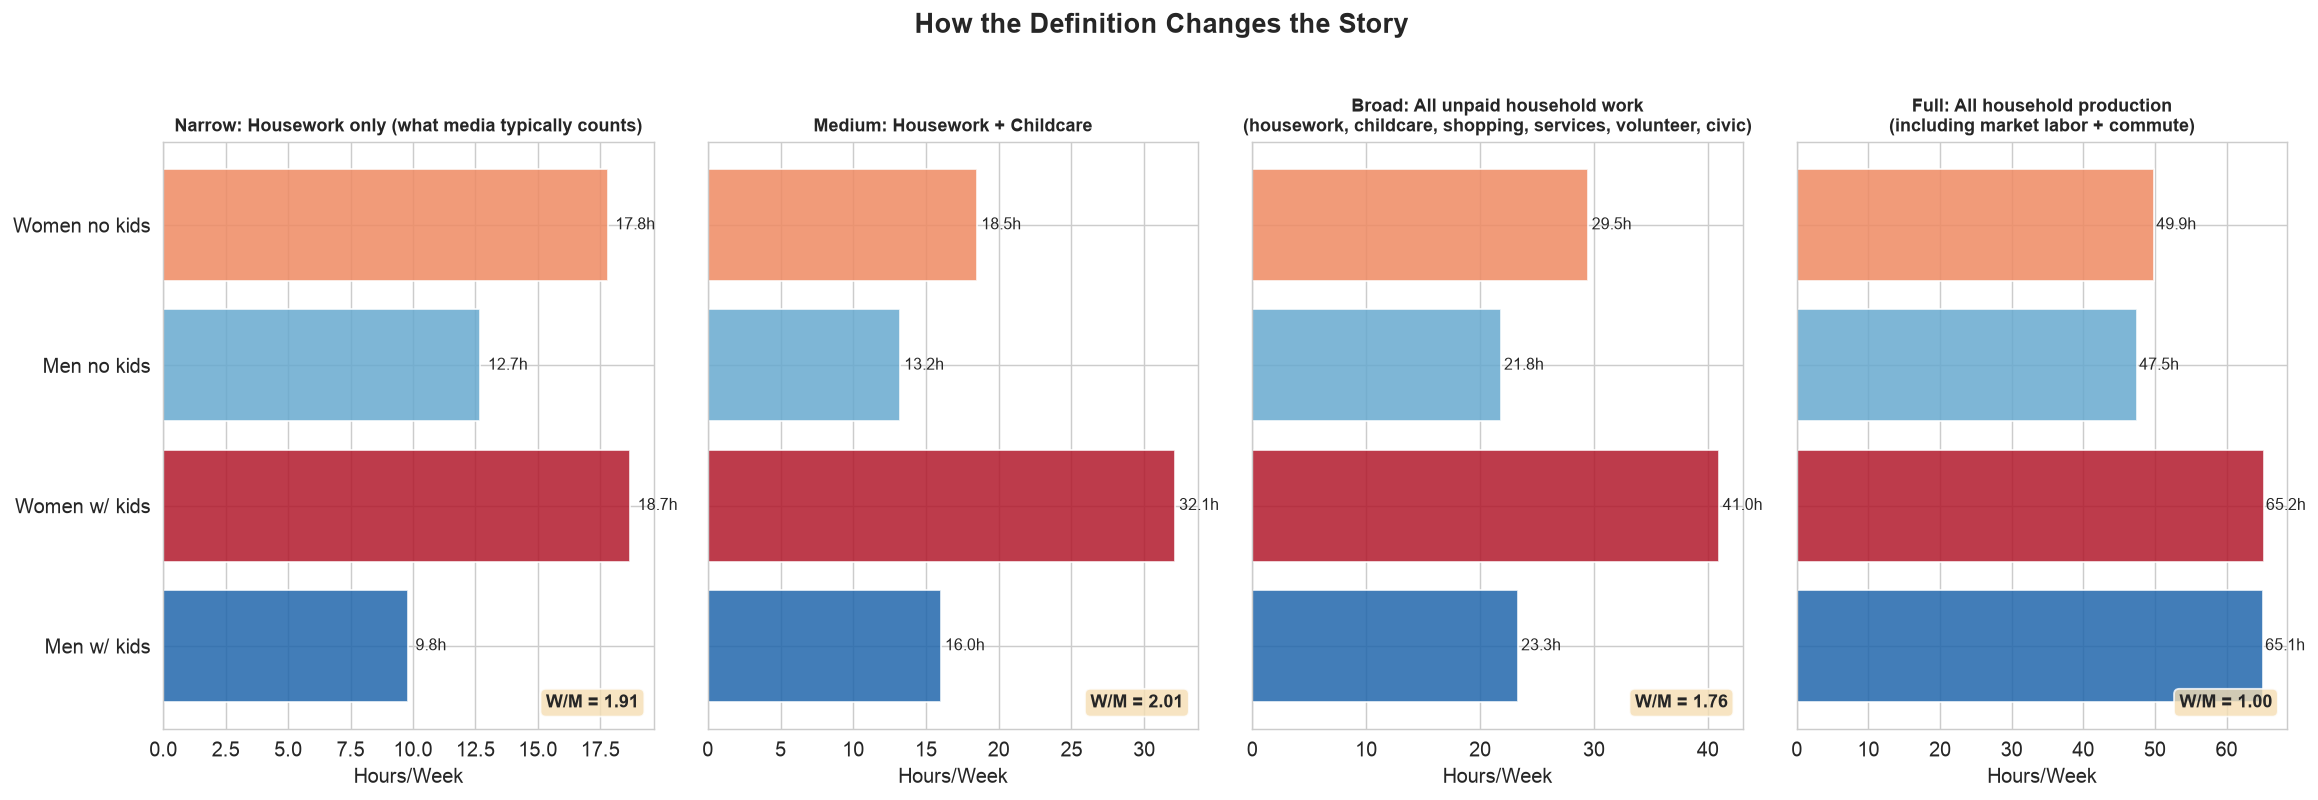

In [11]:
definitions = {
    'Narrow: Housework only (what media typically counts)':
        ['housework_home_maintenance'],
    'Medium: Housework + Childcare':
        ['housework_home_maintenance', 'childcare_household'],
    'Broad: All unpaid household work\n(housework, childcare, shopping, services, volunteer, civic)':
        ['housework_home_maintenance', 'childcare_household', 'care_nonhh_members',
         'shopping', 'prof_personal_services', 'household_services', 'civic_gov', 'volunteer',
         'travel_housework', 'travel_childcare', 'travel_nonhh_care',
         'travel_shopping', 'travel_volunteer', 'travel_civic'],
    'Full: All household production\n(including market labor + commute)':
        category_cols,
}

fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)

for ax_idx, (title, cols) in enumerate(definitions.items()):
    ax = axes[ax_idx]
    groups = ['Men w/ kids', 'Women w/ kids', 'Men no kids', 'Women no kids']
    vals = [summary.loc[g, cols].sum() for g in groups]
    colors = [PALETTE[g] for g in groups]

    bars = ax.barh(groups, vals, color=colors, alpha=0.85)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Hours/Week')

    # Add value labels
    for bar, val in zip(bars, vals):
        ax.text(val + 0.3, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}h', va='center', fontsize=9)

    # Compute ratio
    m_kids = summary.loc['Men w/ kids', cols].sum()
    w_kids = summary.loc['Women w/ kids', cols].sum()
    ratio = w_kids / m_kids if m_kids > 0 else float('inf')
    ax.text(0.97, 0.03, f'W/M = {ratio:.2f}', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.suptitle('How the Definition Changes the Story',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/narrow_vs_broad.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Distribution: Not Just Means

Box plots showing the distribution of total household production for each group.

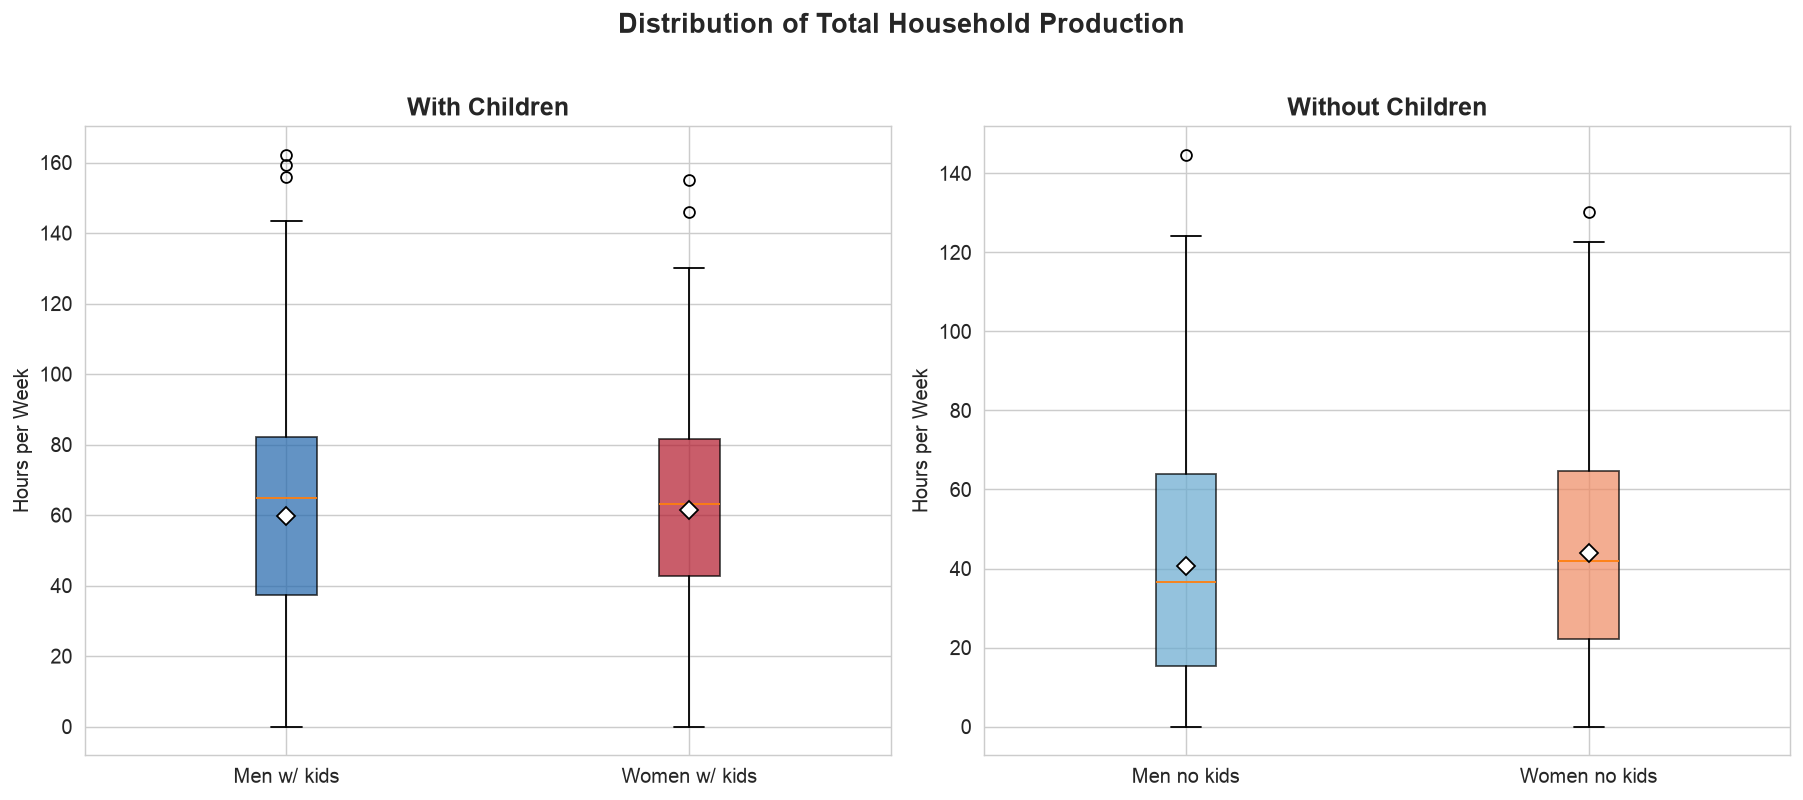

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, kid_status, groups in [
    (axes[0], 'With Children', ['Men w/ kids', 'Women w/ kids']),
    (axes[1], 'Without Children', ['Men no kids', 'Women no kids']),
]:
    data = []
    labels = []
    for g in groups:
        subset = df[df['group'] == g]
        data.append(subset['total_household_production'] * MIN_DAY_TO_HRS_WEEK)
        labels.append(g)

    bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, showmeans=True,
                    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7))
    for patch, g in zip(bp['boxes'], groups):
        patch.set_facecolor(PALETTE[g])
        patch.set_alpha(0.7)

    ax.set_ylabel('Hours per Week')
    ax.set_title(kid_status)

plt.suptitle('Distribution of Total Household Production',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Key Findings

In [13]:
print('=' * 80)
print('KEY FINDINGS')
print('=' * 80)

# 1. Housework only
hw_m = summary.loc['Men w/ kids', 'housework_home_maintenance']
hw_w = summary.loc['Women w/ kids', 'housework_home_maintenance']
print(f'\n1. HOUSEWORK ONLY (cleaning, cooking, laundry, lawn, maintenance):')
print(f'   Married men with kids:   {hw_m:.1f} hrs/week')
print(f'   Married women with kids: {hw_w:.1f} hrs/week')
print(f'   Women do {hw_w/hw_m:.1f}× what men do. Gap: {hw_w - hw_m:.1f} hrs/week')

# 2. Adding childcare
cc_m = summary.loc['Men w/ kids', 'childcare_household']
cc_w = summary.loc['Women w/ kids', 'childcare_household']
print(f'\n2. ADDING CHILDCARE (care, playing, driving kids, attending events):')
print(f'   Married men:   {hw_m + cc_m:.1f} hrs/week')
print(f'   Married women: {hw_w + cc_w:.1f} hrs/week')
print(f'   Women do {(hw_w+cc_w)/(hw_m+cc_m):.2f}× what men do. Gap: {(hw_w+cc_w)-(hw_m+cc_m):.1f} hrs/week')

# 3. Adding market labor
ml_m = summary.loc['Men w/ kids', 'market_labor']
ml_w = summary.loc['Women w/ kids', 'market_labor']
cm_m = summary.loc['Men w/ kids', 'commute']
cm_w = summary.loc['Women w/ kids', 'commute']
print(f'\n3. ADDING MARKET LABOR + COMMUTE:')
print(f'   Married men:   {hw_m + cc_m + ml_m + cm_m:.1f} hrs/week')
print(f'   Married women: {hw_w + cc_w + ml_w + cm_w:.1f} hrs/week')
total_so_far_m = hw_m + cc_m + ml_m + cm_m
total_so_far_w = hw_w + cc_w + ml_w + cm_w
print(f'   Ratio: {total_so_far_w/total_so_far_m:.2f}× (women/men). Gap: {total_so_far_w - total_so_far_m:.1f} hrs/week')

# 4. Total
print(f'\n4. TOTAL HOUSEHOLD PRODUCTION (all 16 categories):')
print(f'   Married men with kids:   {summary.loc["Men w/ kids", "total_household_production"]:.1f} hrs/week')
print(f'   Married women with kids: {summary.loc["Women w/ kids", "total_household_production"]:.1f} hrs/week')
ratio_total = summary.loc['Women w/ kids', 'total_household_production'] / summary.loc['Men w/ kids', 'total_household_production']
print(f'   Ratio: {ratio_total:.2f}× (women/men)')
print(f'   Difference: {summary.loc["Men w/ kids", "total_household_production"] - summary.loc["Women w/ kids", "total_household_production"]:.1f} hrs/week (men - women)')

# 5. The key insight
print(f'\n5. THE KEY INSIGHT:')
print(f'   When media reports say "men don\'t share the housework," they\'re counting only')
print(f'   category 1 (housework): women do {hw_w/hw_m:.1f}× what men do.')
print(f'   But when you count everything a couple must do to maintain a household —')
print(f'   including the 38+ hours/week men spend earning income and commuting —')
print(f'   the total is nearly identical: {summary.loc["Men w/ kids", "total_household_production"]:.0f}h vs {summary.loc["Women w/ kids", "total_household_production"]:.0f}h per week.')
print(f'   The difference is in the COMPOSITION, not the total.')
print(f'   Men contribute through market labor; women contribute through housework + childcare.')
print(f'   Both are essential to maintaining a household.')

KEY FINDINGS

1. HOUSEWORK ONLY (cleaning, cooking, laundry, lawn, maintenance):
   Married men with kids:   9.8 hrs/week
   Married women with kids: 18.7 hrs/week
   Women do 1.9× what men do. Gap: 8.9 hrs/week

2. ADDING CHILDCARE (care, playing, driving kids, attending events):
   Married men:   16.0 hrs/week
   Married women: 32.1 hrs/week
   Women do 2.01× what men do. Gap: 16.1 hrs/week

3. ADDING MARKET LABOR + COMMUTE:
   Married men:   57.8 hrs/week
   Married women: 56.3 hrs/week
   Ratio: 0.97× (women/men). Gap: -1.5 hrs/week

4. TOTAL HOUSEHOLD PRODUCTION (all 16 categories):
   Married men with kids:   65.1 hrs/week
   Married women with kids: 65.2 hrs/week
   Ratio: 1.00× (women/men)
   Difference: -0.1 hrs/week (men - women)

5. THE KEY INSIGHT:
   When media reports say "men don't share the housework," they're counting only
   category 1 (housework): women do 1.9× what men do.
   But when you count everything a couple must do to maintain a household —
   including the 3

---

## Methodology Notes

- **Data**: ATUS 2018 (American Time Use Survey), 9,593 respondents, filtered to 4,571 married respondents (spouse present).
- **Time metric**: ATUS measures a single diary day. We convert to weekly by multiplying by 7. This assumes the diary day is representative of the week (ATUS oversamples weekends to account for variation).
- **Weights**: All means use ATUS final weights (`tufinlwgt`), which adjust for demographic representation and day-of-week.
- **"Married"**: Defined as `trsppres == 1` (spouse present in household). Unmarried partners (n=361) excluded.
- **"Has kids"**: `trchildnum > 0` (any household children under 18).
- **Activity codes**: Mapped from the ATUS 2018 Coding Lexicon (6-digit codes). See the extraction notebook for the full code-to-category mapping.
- **Excluded categories**: Personal care (sleeping, grooming), eating/drinking, socializing/leisure, sports/recreation, religious activities, education, telephone calls — these are not required for household maintenance.

### Limitations

1. **Single diary day**: ATUS measures one day per respondent. Weekly estimates assume that day is representative, though BLS oversamples weekends to mitigate day-of-week bias.
2. **Secondary childcare**: ATUS tracks secondary childcare (child present while doing other activities) separately. This analysis uses only primary activity time. Parents (especially mothers) likely provide more childcare as a secondary activity.
3. **Within-couple variation**: We compare married men and married women as groups, not actual couples. Some couples may have a more equal division than the group averages suggest.
4. **Market labor ≠ "fun"**: Including market labor in household production is defensible because income is essential to maintaining a household. However, many people derive satisfaction from their jobs, so not all work hours are "burden."